In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.shape

(41188, 21)

In [4]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [6]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
print(df['y'].value_counts())
print()
print(df['y'].value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


In [8]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [9]:
categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


job:
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

marital:
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

education:
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

default:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

housing:
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

loan:
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

contact:
con

C:\Users\landg\AppData\Local\Temp\ipykernel_16924\987115423.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns


In [10]:
categorical_columns = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month',
    'day_of_week', 'poutcome', 'y'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


job:
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

marital:
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

education:
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

default:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

housing:
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

loan:
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

contact:
con

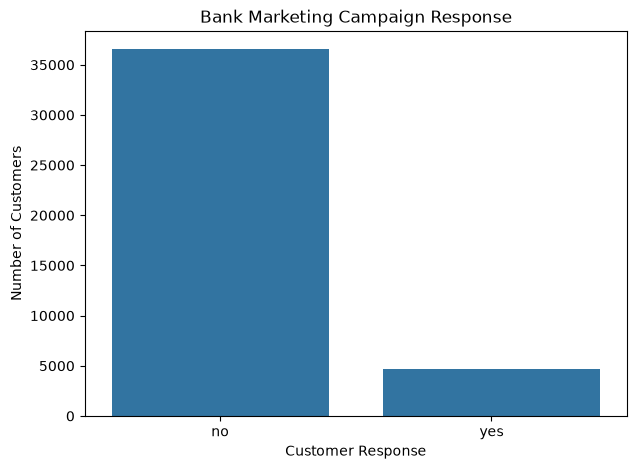

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Bank Marketing Campaign Response')
plt.xlabel('Customer Response')
plt.ylabel('Number of Customers')

plt.show()

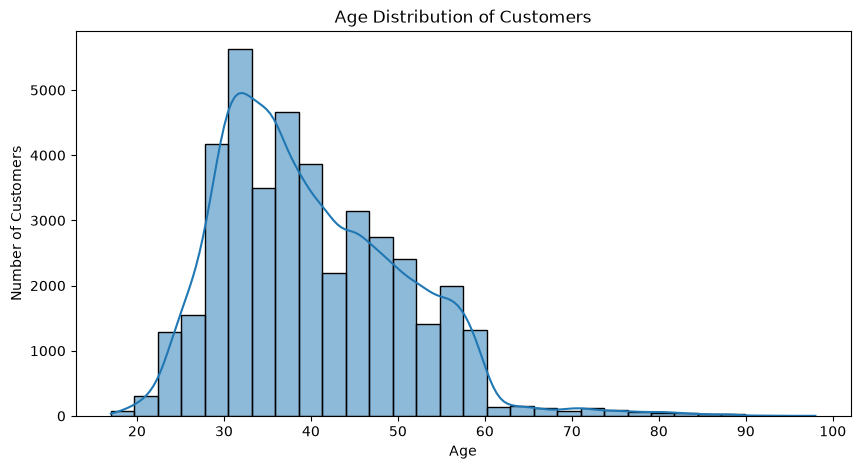

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

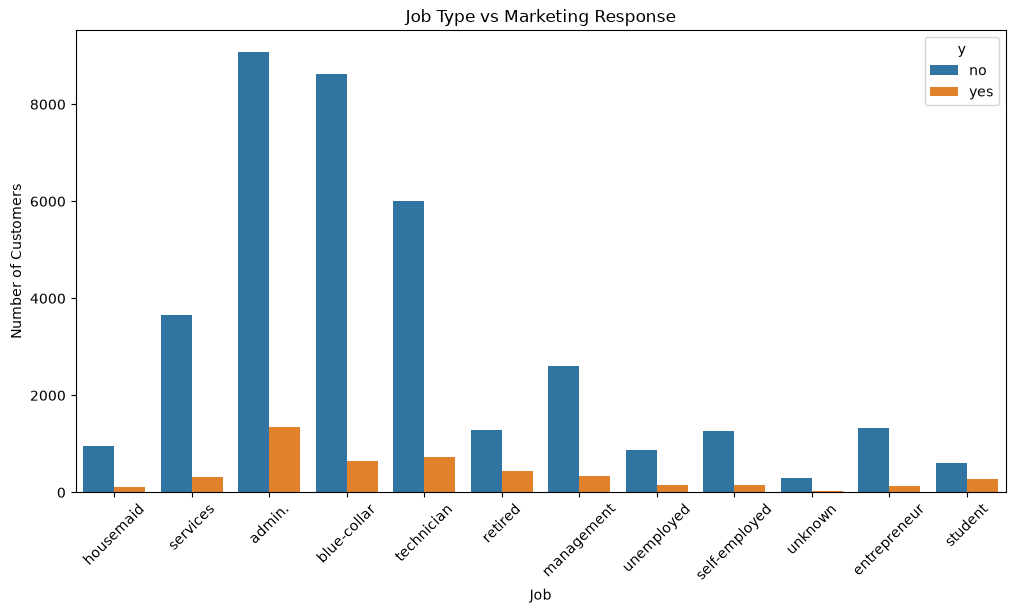

In [13]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='job', hue='y')

plt.title('Job Type vs Marketing Response')
plt.xlabel('Job')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

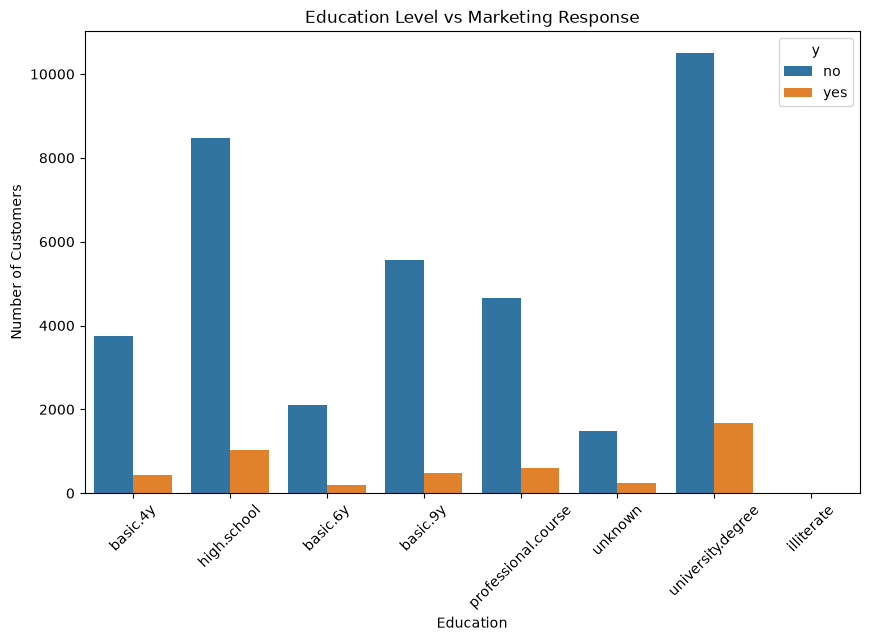

In [14]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='education', hue='y')

plt.title('Education Level vs Marketing Response')
plt.xlabel('Education')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

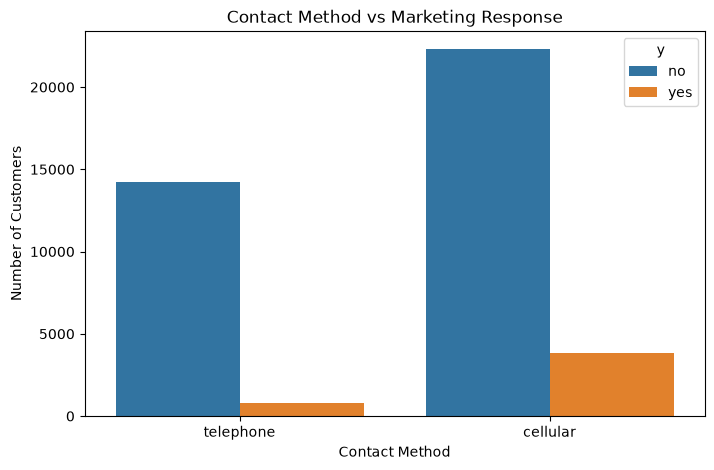

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='contact', hue='y')

plt.title('Contact Method vs Marketing Response')
plt.xlabel('Contact Method')
plt.ylabel('Number of Customers')

plt.show()

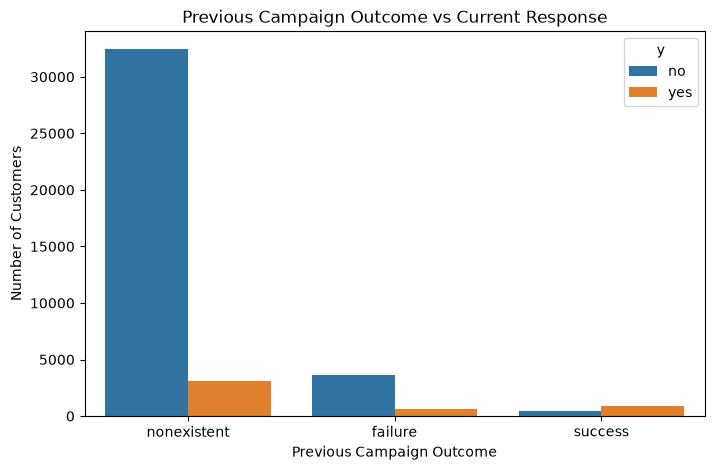

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='poutcome', hue='y')

plt.title('Previous Campaign Outcome vs Current Response')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Number of Customers')

plt.show()

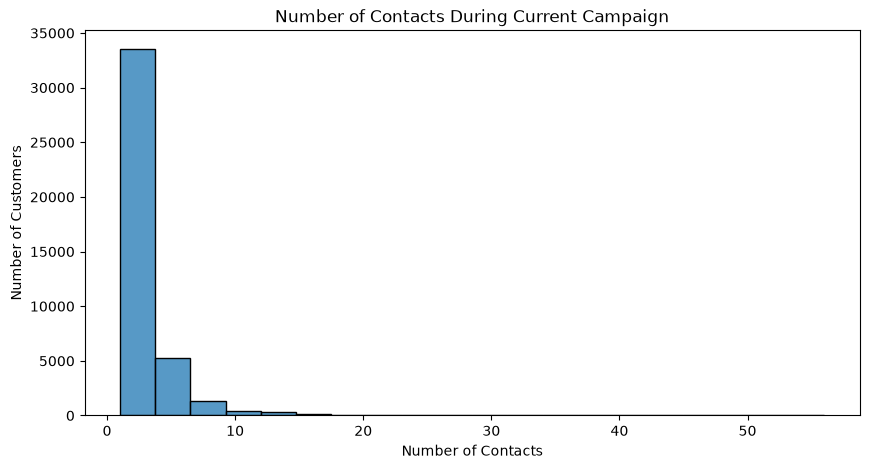

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='campaign', bins=20)

plt.title('Number of Contacts During Current Campaign')
plt.xlabel('Number of Contacts')
plt.ylabel('Number of Customers')

plt.show()

In [18]:
conversion_rate = (df['y'] == 'yes').mean() * 100

print(f"Overall subscription rate: {conversion_rate:.2f}%")

Overall subscription rate: 11.27%


In [19]:
job_conversion = (
    df.groupby('job')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

print(job_conversion.round(2))

job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64


In [20]:
education_conversion = (
    df.groupby('education')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

print(education_conversion.round(2))

education
illiterate             22.22
unknown                14.50
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.20
basic.9y                7.82
Name: y, dtype: float64


In [21]:
contact_conversion = (
    df.groupby('contact')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

print(contact_conversion.round(2))

contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64


In [22]:
poutcome_conversion = (
    df.groupby('poutcome')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

print(poutcome_conversion.round(2))

poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64


In [23]:
campaign_conversion = (
    df.groupby('campaign')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

print(campaign_conversion.head(15).round(2))

campaign
1     13.04
2     11.46
3     10.75
4      9.39
6      7.66
5      7.50
17     6.90
11     6.78
23     6.25
7      6.04
9      6.01
10     5.33
13     4.35
8      4.25
15     3.92
Name: y, dtype: float64


In [24]:
# Create a copy so the original dataset remains unchanged
data = df.copy()

# Convert target variable to binary
data['y'] = data['y'].map({'no': 0, 'yes': 1})

print(data['y'].value_counts())

y
0    36548
1     4640
Name: count, dtype: int64


In [25]:
# Remove duration to avoid post-call information leakage
data = data.drop(columns=['duration'])

print("New shape:", data.shape)

New shape: (41188, 20)


In [26]:
X = data.drop(columns=['y'])
y = data['y']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (41188, 19)
Target shape: (41188,)


In [27]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object', 'str']).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [28]:
X['was_previously_contacted'] = (X['pdays'] != 999).astype(int)

print(X[['pdays', 'was_previously_contacted']].head(10))

   pdays  was_previously_contacted
0    999                         0
1    999                         0
2    999                         0
3    999                         0
4    999                         0
5    999                         0
6    999                         0
7    999                         0
8    999                         0
9    999                         0


In [29]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object', 'str']).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_previously_contacted']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (32950, 20)
Testing set: (8238, 20)


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [32]:
# Numerical features
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Categorical features
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (32950, 63)
Testing data after preprocessing: (8238, 63)


In [35]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

In [36]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [37]:
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
logistic_roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Results")
print("-" * 35)
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_roc_auc:.4f}")

Logistic Regression Results
-----------------------------------
Accuracy : 0.8349
Precision: 0.3675
Recall   : 0.6455
F1 Score : 0.4683
ROC-AUC  : 0.8010


In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

           0       0.95      0.86      0.90      7310
           1       0.37      0.65      0.47       928

    accuracy                           0.83      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.83      0.85      8238



In [40]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42,
                class_weight="balanced",
                max_depth=8
            )
        )
    ]
)

In [41]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [42]:
y_pred_tree = decision_tree_model.predict(X_test)
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

In [43]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree)
tree_recall = recall_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree)
tree_roc_auc = roc_auc_score(y_test, y_prob_tree)

print("Decision Tree Results")
print("-" * 35)
print(f"Accuracy : {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall   : {tree_recall:.4f}")
print(f"F1 Score : {tree_f1:.4f}")
print(f"ROC-AUC  : {tree_roc_auc:.4f}")

Decision Tree Results
-----------------------------------
Accuracy : 0.8335
Precision: 0.3618
Recall   : 0.6261
F1 Score : 0.4586
ROC-AUC  : 0.7788


In [44]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.95      0.86      0.90      7310
           1       0.36      0.63      0.46       928

    accuracy                           0.83      8238
   macro avg       0.65      0.74      0.68      8238
weighted avg       0.88      0.83      0.85      8238



In [45]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

In [46]:
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [47]:
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [48]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("-" * 35)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

Random Forest Results
-----------------------------------
Accuracy : 0.8779
Precision: 0.4602
Recall   : 0.4860
F1 Score : 0.4727
ROC-AUC  : 0.7865


In [49]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93      7310
           1       0.46      0.49      0.47       928

    accuracy                           0.88      8238
   macro avg       0.70      0.71      0.70      8238
weighted avg       0.88      0.88      0.88      8238



In [50]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall,
        rf_recall
    ],
    "F1 Score": [
        logistic_f1,
        tree_f1,
        rf_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        tree_roc_auc,
        rf_roc_auc
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8349,0.3675,0.6455,0.4683,0.8010
1,Decision Tree,0.8335,0.3618,0.6261,0.4586,0.7788
2,Random Forest,0.8779,0.4602,0.4860,0.4727,0.7865


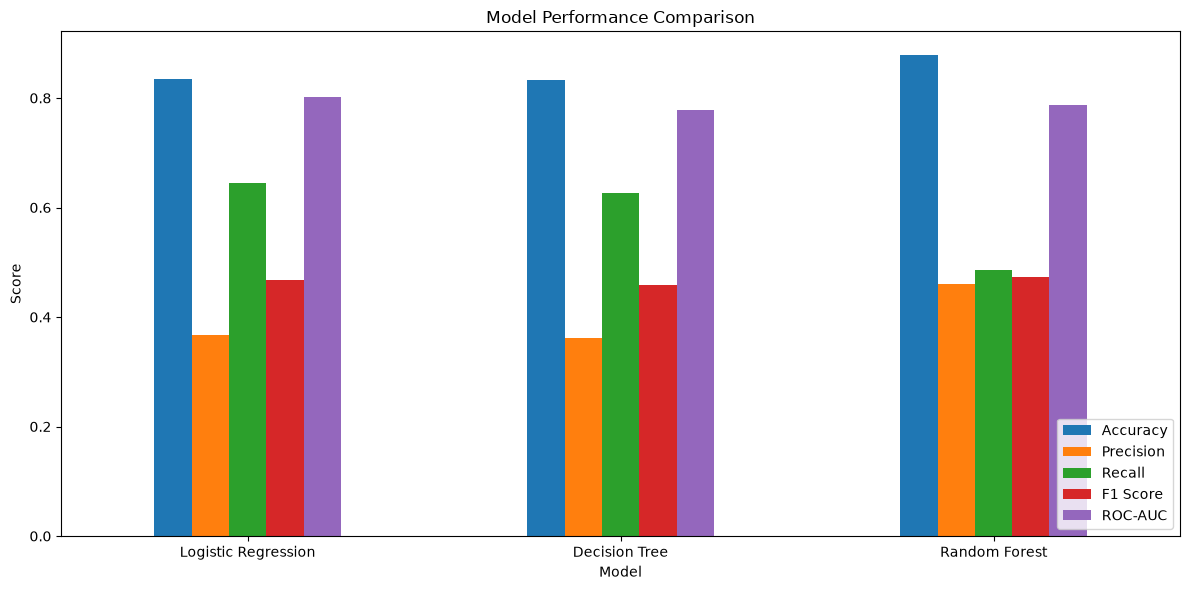

In [51]:
results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

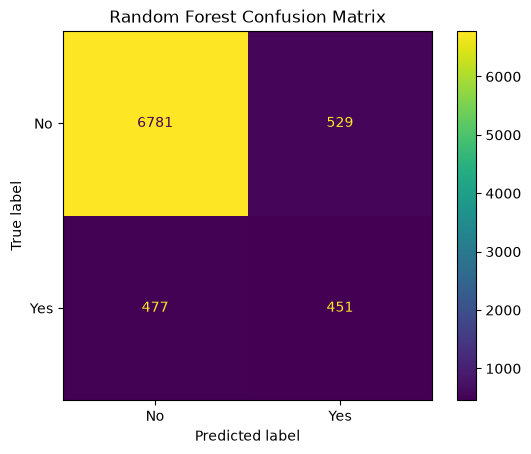

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [53]:
# Extract the trained Random Forest model
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
0,num__age,0.142018
7,num__euribor3m,0.120962
1,num__campaign,0.079778
8,num__nr.employed,0.064621
4,num__emp.var.rate,0.038141
6,num__cons.conf.idx,0.025035
5,num__cons.price.idx,0.024895
37,cat__housing_no,0.018575
39,cat__housing_yes,0.018414
10,cat__job_admin.,0.017319


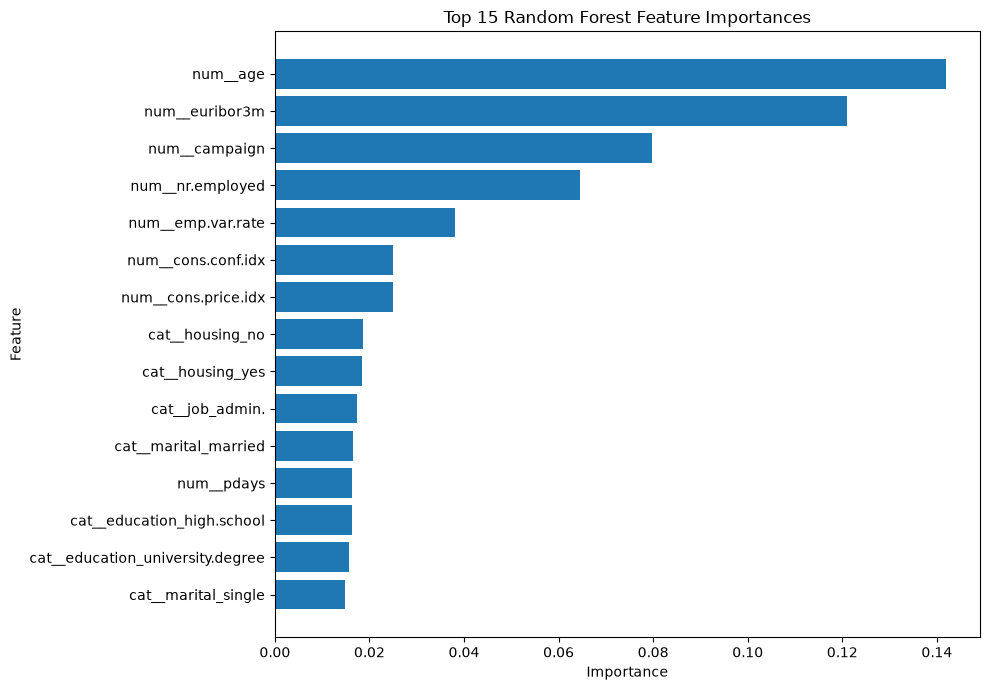

In [54]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [55]:
from sklearn.model_selection import RandomizedSearchCV

In [56]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

param_distributions = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [8, 12, 16, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

In [57]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Randomized search completed.")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Randomized search completed.


In [58]:
print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(f"{rf_search.best_score_:.4f}")

Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 16}

Best cross-validation F1-score:
0.4831


In [59]:
best_rf_model = rf_search.best_estimator_

y_pred_tuned_rf = best_rf_model.predict(X_test)
y_prob_tuned_rf = best_rf_model.predict_proba(X_test)[:, 1]

tuned_rf_accuracy = accuracy_score(y_test, y_pred_tuned_rf)
tuned_rf_precision = precision_score(y_test, y_pred_tuned_rf)
tuned_rf_recall = recall_score(y_test, y_pred_tuned_rf)
tuned_rf_f1 = f1_score(y_test, y_pred_tuned_rf)
tuned_rf_roc_auc = roc_auc_score(y_test, y_prob_tuned_rf)

print("Tuned Random Forest Results")
print("-" * 40)
print(f"Accuracy : {tuned_rf_accuracy:.4f}")
print(f"Precision: {tuned_rf_precision:.4f}")
print(f"Recall   : {tuned_rf_recall:.4f}")
print(f"F1 Score : {tuned_rf_f1:.4f}")
print(f"ROC-AUC  : {tuned_rf_roc_auc:.4f}")

Tuned Random Forest Results
----------------------------------------
Accuracy : 0.8688
Precision: 0.4413
Recall   : 0.6196
F1 Score : 0.5155
ROC-AUC  : 0.8119


In [60]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Baseline",
        "Random Forest - Tuned"
    ],
    "Accuracy": [
        rf_accuracy,
        tuned_rf_accuracy
    ],
    "Precision": [
        rf_precision,
        tuned_rf_precision
    ],
    "Recall": [
        rf_recall,
        tuned_rf_recall
    ],
    "F1 Score": [
        rf_f1,
        tuned_rf_f1
    ],
    "ROC-AUC": [
        rf_roc_auc,
        tuned_rf_roc_auc
    ]
})

rf_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest - Baseline,0.8779,0.4602,0.4860,0.4727,0.7865
1,Random Forest - Tuned,0.8688,0.4413,0.6196,0.5155,0.8119


In [61]:
print("Tuned Random Forest Classification Report")
print("-" * 50)

print(
    classification_report(
        y_test,
        y_pred_tuned_rf,
        target_names=["No", "Yes"]
    )
)

Tuned Random Forest Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

          No       0.95      0.90      0.92      7310
         Yes       0.44      0.62      0.52       928

    accuracy                           0.87      8238
   macro avg       0.70      0.76      0.72      8238
weighted avg       0.89      0.87      0.88      8238



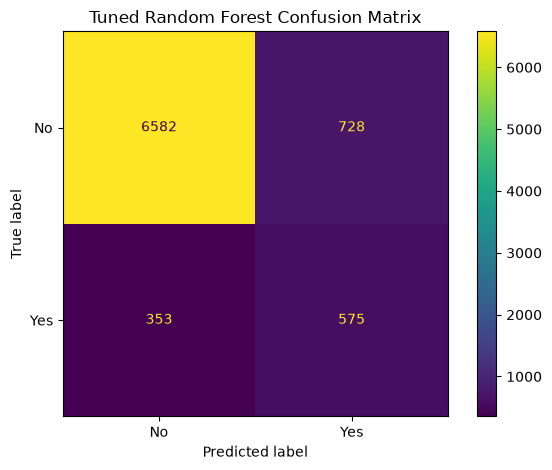

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned_rf,
    display_labels=["No", "Yes"]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [63]:
rf_classifier = best_rf_model.named_steps["classifier"]

feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
7,num__euribor3m,0.138547
8,num__nr.employed,0.128014
4,num__emp.var.rate,0.077950
0,num__age,0.068185
5,num__cons.price.idx,0.046237
6,num__cons.conf.idx,0.042676
1,num__campaign,0.038553
2,num__pdays,0.031102
62,cat__poutcome_success,0.025900
9,num__was_previously_contacted,0.023633


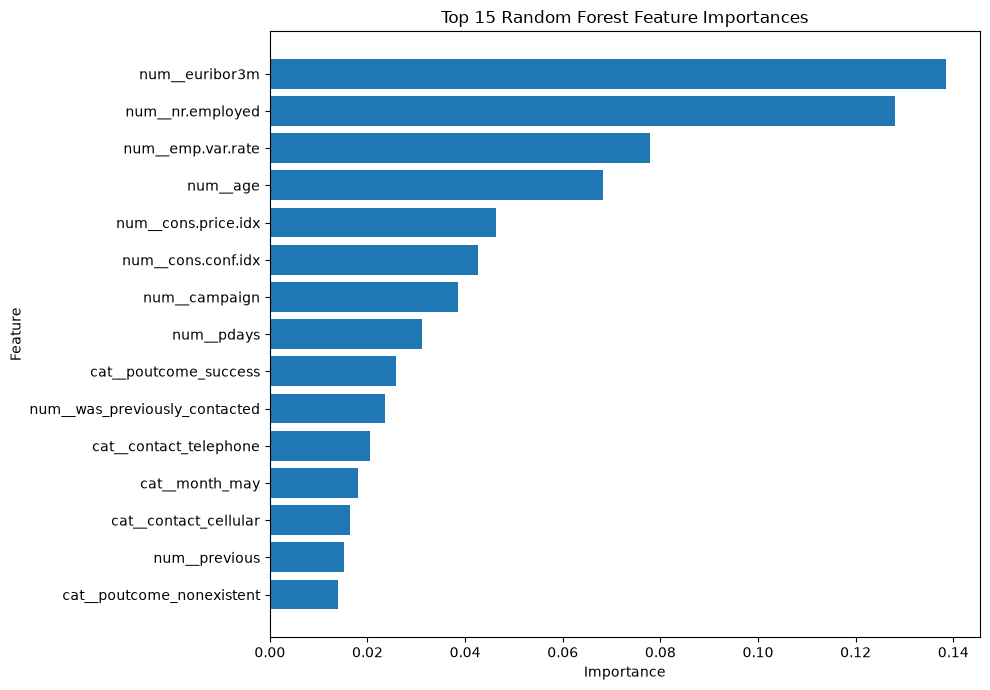

In [64]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [65]:
import joblib

joblib.dump(
    best_rf_model,
    "bank_marketing_random_forest.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [66]:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier

feature_selector_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "selector",
            SelectFromModel(
                RandomForestClassifier(
                    n_estimators=200,
                    random_state=42,
                    class_weight="balanced",
                    n_jobs=-1
                ),
                threshold="median"
            )
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=16,
                min_samples_split=5,
                min_samples_leaf=1,
                max_features="sqrt",
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

print("Feature selection pipeline created.")

Feature selection pipeline created.


In [67]:
feature_selector_model.fit(X_train, y_train)

print("Feature selection model trained successfully.")

Feature selection model trained successfully.


In [68]:
y_pred_selected = feature_selector_model.predict(X_test)
y_prob_selected = feature_selector_model.predict_proba(X_test)[:, 1]

selected_accuracy = accuracy_score(y_test, y_pred_selected)
selected_precision = precision_score(y_test, y_pred_selected)
selected_recall = recall_score(y_test, y_pred_selected)
selected_f1 = f1_score(y_test, y_pred_selected)
selected_roc_auc = roc_auc_score(y_test, y_prob_selected)

print("Random Forest with Feature Selection")
print("-" * 45)
print(f"Accuracy : {selected_accuracy:.4f}")
print(f"Precision: {selected_precision:.4f}")
print(f"Recall   : {selected_recall:.4f}")
print(f"F1 Score : {selected_f1:.4f}")
print(f"ROC-AUC  : {selected_roc_auc:.4f}")

Random Forest with Feature Selection
---------------------------------------------
Accuracy : 0.8699
Precision: 0.4441
Recall   : 0.6164
F1 Score : 0.5162
ROC-AUC  : 0.8042


In [69]:
final_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Random Forest + Feature Selection"
    ],
    "Accuracy": [
        tuned_rf_accuracy,
        selected_accuracy
    ],
    "Precision": [
        tuned_rf_precision,
        selected_precision
    ],
    "Recall": [
        tuned_rf_recall,
        selected_recall
    ],
    "F1 Score": [
        tuned_rf_f1,
        selected_f1
    ],
    "ROC-AUC": [
        tuned_rf_roc_auc,
        selected_roc_auc
    ]
})

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.8688,0.4413,0.6196,0.5155,0.8119
1,Random Forest + Feature Selection,0.8699,0.4441,0.6164,0.5162,0.8042


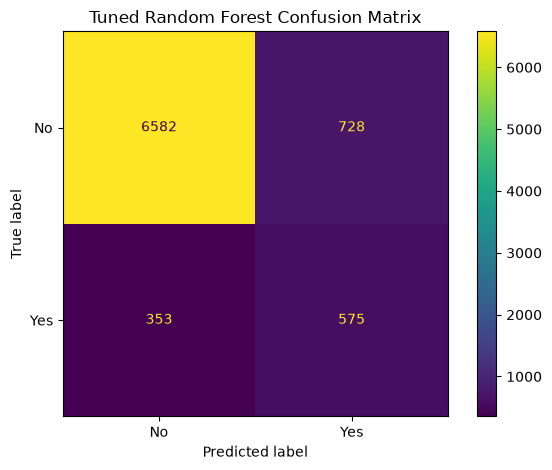

In [70]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned_rf,
    display_labels=["No", "Yes"]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [71]:

rf_classifier = best_rf_model.named_steps["classifier"]

feature_names = best_rf_model.named_steps["preprocessor"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
7,num__euribor3m,0.138547
8,num__nr.employed,0.128014
4,num__emp.var.rate,0.077950
0,num__age,0.068185
5,num__cons.price.idx,0.046237
6,num__cons.conf.idx,0.042676
1,num__campaign,0.038553
2,num__pdays,0.031102
62,cat__poutcome_success,0.025900
9,num__was_previously_contacted,0.023633


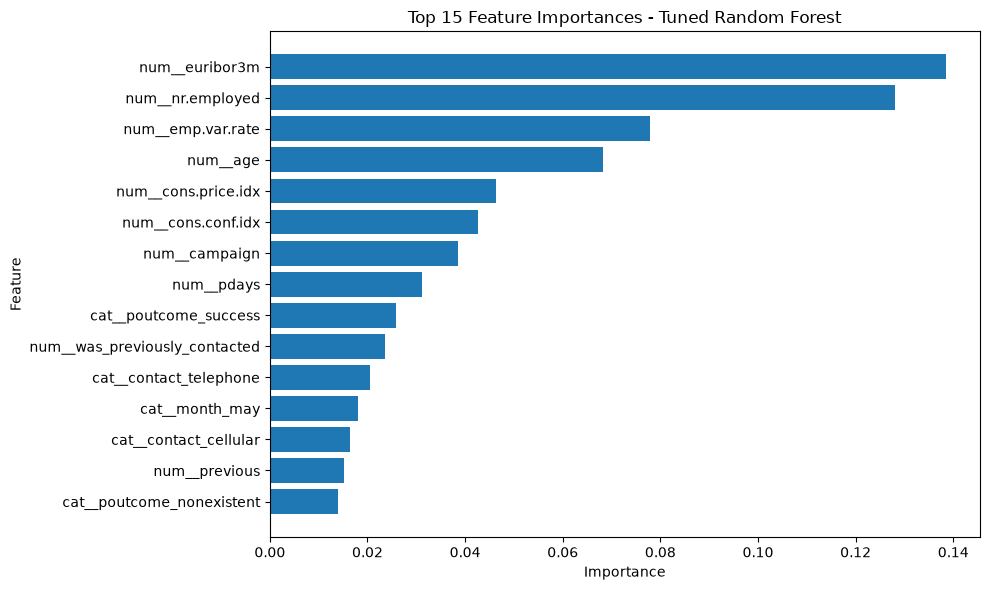

In [72]:
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Tuned Random Forest")

plt.tight_layout()
plt.show()

In [73]:
import joblib

joblib.dump(best_rf_model, "bank_marketing_random_forest.pkl")

print("Final model saved successfully.")

Final model saved successfully.


In [74]:
import os

print(os.path.exists("bank_marketing_random_forest.pkl"))

True


In [75]:
import sklearn
import pandas
import numpy
import matplotlib
import seaborn
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.9.0
pandas: 3.0.5
numpy: 2.5.2
matplotlib: 3.11.1
seaborn: 0.13.2
joblib: 1.5.3
